# Ⅰ第5回 演習1 学習済みの ResNet18 を自分の写真に合わせる

**問い**：大量の画像（ImageNet：1000 種類・約 128 万枚）で学習済みのモデルを使うと，自分の少ない写真でも正解率は上がるか．

- 第4回 演習1 の自分のセル（`course1/day4/ex1.ipynb`）を **コピーして貼り**，下の表の所だけ直す
- コードパターンを理解するため，**LLM（ChatGPT・Copilot など）を使わずに** やってみよう
- 各テンプレートの下の `check(...)` で `OK` が出たら次へ進む．止まったら，出たメッセージの「ヒント」を読む．それでも分からなければ，テンプレートの上の「ヒント（ほぼ答え）」を開く
- 先に **凍結**（最後の層だけ学習）で①〜⑫を通し，そのあと⑦〜⑫を **微調整**（全部の層を学習）で書き直す

## (0) 番号の設定

In [1]:
# ===== (0) 番号の設定 =====
MEMBER_NO = 1                 # ← グループ内の自分の番号 (1〜5)．presenter はこの番号の順に演習ごとに交代する

# 授業用フォルダ（AI_TD）のルートを import パスに追加する（ノートブックをどこから開いても動く）
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".dlcourse_root").exists())
sys.path.insert(0, str(ROOT))
print("作業フォルダ:", ROOT)

作業フォルダ: /Users/itagakisogo/AI_TD


## (1) 自分のデータ

第4回と同じ `assets/mydata/` を使う（無ければケーブル画像で進む）．

In [2]:
from common.mydata import image_dir
from common.stepcheck import check
IMAGE_DIR = str(image_dir())     # ③ではこのフォルダを読む
for d in sorted(Path(IMAGE_DIR).iterdir()):
    if d.is_dir():
        print(f"{d.name:20s} {len(list(d.glob('*.jpg')))} 枚")

away                 42 枚
home                 48 枚


## 第4回 演習1 から変える所

| テンプレート | 変える所 |
|---|---|
| ① | `from torchvision import models` を足す（学習済みモデルを読むため） |
| ② | `Resize((224, 224))` にし，`ToTensor()` のあとに `transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])` を足す（ImageNet で学習したときと同じ入力にする） |
| ⑦ | 下の「新しく使う書き方」 |
| ⑧⑨ | 凍結は `optim.Adam(model.fc.parameters(), lr=0.001)`，微調整は `optim.Adam(model.parameters(), lr=0.0001)` |
| ⑩ | 凍結は `EPOCHS = 20`，微調整は `EPOCHS = 10` |
| ほか | 同じでよい |

## 新しく使う書き方（⑦）

**凍結**（最後の層だけ学習する）

```python
NUM_CLASSES = len(full_dataset.classes)                    # クラス数
from torchvision.models import ResNet18_Weights
model = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)   # 学習済みの ResNet18 を読む（初回はダウンロード 45MB）
for param in model.parameters():                           # 全パラメータを固定する（勾配を計算しない）
    param.requires_grad = False
num_ftrs = model.fc.in_features                            # 最終層に入る数（512）
model.fc = nn.Linear(num_ftrs, NUM_CLASSES)                # 最終層（1000 クラス用）をクラス数に置き換える
for param in model.fc.parameters():                        # 置き換えた最終層だけを学習対象にする
    param.requires_grad = True
model = model.to(device)
dummy_input = torch.randn(1, 3, 224, 224).to(device)       # ダミーデータで出力の形を確かめる
output = model(dummy_input)
print("出力の形状: ", output.size())                        # torch.Size([1, クラス数]) になる
```

**微調整**（全部の層を学習する）：上の `for` を 2 つとも書かない．⑧⑨は `optim.Adam(model.parameters(), lr=0.0001)` にし，学習率を 1/10 にする．

## 予測（実行する前に書く）

このセルをダブルクリックして書き込む．

- 第4回の自分の CNN のテスト正解率（シード 0）：100％
- ResNet18 凍結：100％　微調整：100％

## データ準備フェーズ（①〜④）

### コードテンプレート①：ライブラリのインポート

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from torch.utils.data import Dataset
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import random
import numpy as np
from torchvision.datasets import ImageFolder
from torchvision import models
```

</details>

In [19]:
# PyTorch 本体と，ニューラルネットワーク・最適化・画像処理の部品を読み込む
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from torchvision import models

from torch.utils.data import Dataset
# グラフを描く道具
import matplotlib.pyplot as plt
import seaborn as sns
# 処理の進み具合をバーで表示する道具
from tqdm import tqdm
import random
import numpy as np

# 追加
# フォルダごとに分けた画像を読み込む道具（フォルダ名がクラスになる）
from torchvision.datasets import ImageFolder

In [20]:
check("①", globals(), size=224)

① OK


### コードテンプレート②：データ前処理

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
}
```

</details>

In [31]:
# 前処理：訓練用・検証用とも 64×64 に縮小してからテンソルに変換する
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
}

In [32]:
check("②", globals(), size=224)

② OK


### コードテンプレート③：データの読み込みと分割（乱数の種の固定）

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
full_dataset = ImageFolder(root=IMAGE_DIR)
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(0)
train_size = int(0.7 * len(full_dataset))
val_size = int(0.15 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size
train_subset, val_subset, test_subset = random_split(full_dataset, [train_size, val_size, test_size])
class CustomDataset(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform
    def __getitem__(self, index):
        image, label = self.subset[index]
        if self.transform:
            image = self.transform(image)
        return image, label
    def __len__(self):
        return len(self.subset)
train_dataset = CustomDataset(train_subset, transform=data_transforms['train'])
val_dataset = CustomDataset(val_subset, transform=data_transforms['val'])
test_dataset = CustomDataset(test_subset, transform=data_transforms['val'])
```

</details>

In [33]:
# class0／class1 フォルダの画像を読み込む（ラベルはフォルダで決まる）
full_dataset = ImageFolder(root=IMAGE_DIR)

# 乱数の種を固定して，同じ条件の結果を再現しやすくする（機種や版が違うと一致しないこともある）
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.cuda.manual_seed(0)
if torch.backends.mps.is_available():
    torch.mps.manual_seed(0)

# 全 200 枚を 70% 訓練用・15% 検証用・15% テスト用に分ける（テスト用は学習にも調整にも使わない）
train_size = int(0.7 * len(full_dataset))
val_size = int(0.15 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

train_subset, val_subset, test_subset = random_split(
    full_dataset, [train_size, val_size, test_size]
)

# 分けたデータに，訓練用・検証用それぞれの前処理をかけるための入れ物
class CustomDataset(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        image, label = self.subset[index]
        if self.transform:
            image = self.transform(image)
        return image, label
    
    def __len__(self):
        return len(self.subset)

# 訓練用・検証用・テスト用に前処理を割り当てる（テスト用は検証用と同じ前処理）
train_dataset = CustomDataset(train_subset, transform=data_transforms['train'])
val_dataset = CustomDataset(val_subset, transform=data_transforms['val'])
test_dataset = CustomDataset(test_subset, transform=data_transforms['val'])

print(f" Dataset Loaded: {IMAGE_DIR}")
print(f"     Total samples: {len(full_dataset)}")
print(f"     Train samples: {len(train_dataset)}")
print(f"     Val samples  : {len(val_dataset)}")
print(f"     Test samples : {len(test_dataset)}")

 Dataset Loaded: /Users/itagakisogo/AI_TD/assets/mydata
     Total samples: 90
     Train samples: 62
     Val samples  : 13
     Test samples : 15


In [34]:
check("③", globals(), size=224)

クラス ['away', 'home']｜訓練 62・検証 13・テスト 15 枚
③ OK


### コードテンプレート④：データローダの作成

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
BATCH_SIZE = 8
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
```

</details>

In [35]:
# 一度にまとめて流す枚数（ミニバッチの大きさ）
BATCH_SIZE = 8
# データをミニバッチに分けて順に取り出す仕組み（訓練用は毎回並びを混ぜる）
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [36]:
check("④", globals(), size=224)

④ OK


## 学習設定フェーズ（⑤〜⑨）

### コードテンプレート⑤：使用デバイスの選択

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"使用デバイス: {device}")
```

</details>

In [37]:
# 計算に使う装置を選ぶ：NVIDIA の GPU → Apple の GPU（mps）→ CPU の順
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"使用デバイス: {device}")

使用デバイス: mps


In [38]:
check("⑤", globals(), size=224)

⑤ OK


### コードテンプレート⑥：ミニバッチの形状確認

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
imgs, _ = next(iter(train_loader))
c, h, w = imgs[0].shape
print(imgs.shape)
```

</details>

ミニバッチサイズ: 8
チャネル数: 3
画像の高さ: 224
画像の幅: 224
torch.Size([8, 3, 224, 224])


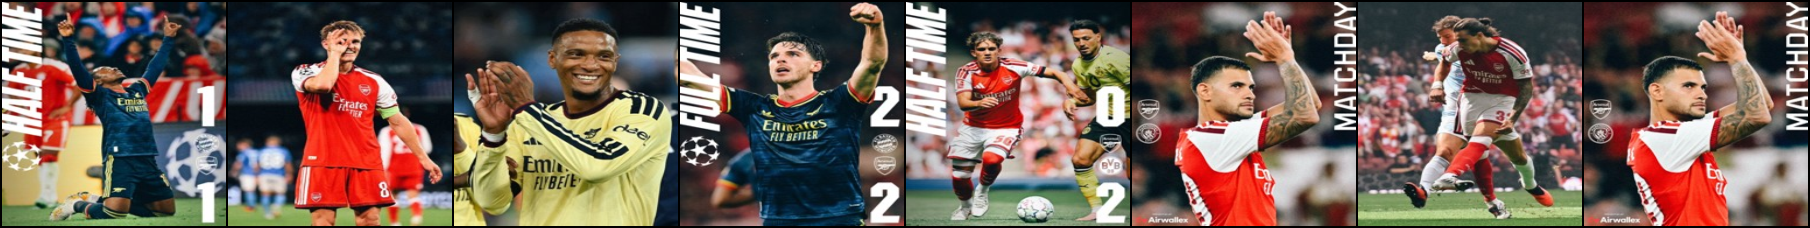

In [39]:
# ミニバッチを 1 つ取り出し，形（枚数・チャネル・高さ・幅）を確かめる
imgs, _ = next(iter(train_loader))
c, h, w = imgs[0].shape
print("ミニバッチサイズ:", len(imgs))
print("チャネル数:", c)
print("画像の高さ:", h)
print("画像の幅:", w)
print(imgs.shape)

# 取り出した画像を並べて表示する
img = torchvision.utils.make_grid(imgs)
img = transforms.functional.to_pil_image(img)
display(img)

In [40]:
check("⑥", globals(), size=224)

⑥ OK


### コードテンプレート⑦：ネットワークの定義（ResNet18・凍結）

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
NUM_CLASSES = len(full_dataset.classes)
from torchvision.models import ResNet18_Weights
model = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
for param in model.parameters():
    param.requires_grad = False
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, NUM_CLASSES)
for param in model.fc.parameters():
    param.requires_grad = True
model = model.to(device)
dummy_input = torch.randn(1, 3, 224, 224).to(device)
output = model(dummy_input)
print("出力の形状: ", output.size())
```

</details>

In [41]:
NUM_CLASSES = len(full_dataset.classes)                    # クラス数
from torchvision.models import ResNet18_Weights
model = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)   # 学習済みの ResNet18 を読む（初回はダウンロード 45MB）
for param in model.parameters():                           # 全パラメータを固定する（勾配を計算しない）
    param.requires_grad = False
num_ftrs = model.fc.in_features                            # 最終層に入る数（512）
model.fc = nn.Linear(num_ftrs, NUM_CLASSES)                # 最終層（1000 クラス用）をクラス数に置き換える
for param in model.fc.parameters():                        # 置き換えた最終層だけを学習対象にする
    param.requires_grad = True
model = model.to(device)
dummy_input = torch.randn(1, 3, 224, 224).to(device)       # ダミーデータで出力の形を確かめる
output = model(dummy_input)
print("出力の形状: ", output.size()) 

出力の形状:  torch.Size([1, 2])


In [42]:
check("⑦", globals(), size=224)

ResNet｜出力の形 (1, 2)｜パラメータ数 11,177,538（うち学習する数 1,026）
⑦ OK


### コードテンプレート⑧⑨：損失関数と最適化手法

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)
```

</details>

In [43]:
# 損失関数：予測と正解のずれを測る（分類で標準の交差エントロピー）
criterion = nn.CrossEntropyLoss()
# 最適化手法：損失が小さくなる向きに重みを少しずつ動かす（学習率 0.001）
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

In [44]:
check("⑧⑨", globals(), size=224)

⑧⑨ OK


## 学習・評価フェーズ（⑩〜⑫）

### コードテンプレート⑩：学習

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
EPOCHS = 20
train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []
import time
_t0 = time.perf_counter()
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs.data, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    train_loss_list.append(train_loss / train_total)
    train_acc_list.append(100.0 * train_correct / train_total)
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    val_loss_list.append(val_loss / val_total)
    val_acc_list.append(100.0 * val_correct / val_total)
train_sec = time.perf_counter() - _t0
```

</details>

In [45]:
EPOCHS = 20          # 授業では試行①②③とも 20 エポックにそろえる
# エポックごとの損失と正解率を記録するリスト
train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []

# 学習時間を測る（授業で追加）
import time
_t0 = time.perf_counter()
# EPOCHS 回，訓練データ全体を繰り返し学習する
for epoch in range(EPOCHS):
    # 訓練モードにする
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [Train]', leave=False):
        images, labels = images.to(device), labels.to(device)

        # 前回の勾配を消す → 予測 → 損失を計算 → 誤差逆伝播で勾配を求める → 重みを更新
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        # 最も確率の高いクラスを予測とし，正解の数を数える
        _, predicted = torch.max(outputs.data, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    
    train_loss /= train_total
    train_accuracy = 100.0 * train_correct / train_total
    train_loss_list.append(train_loss)
    train_acc_list.append(train_accuracy)
    
    # 評価モードにする：ここからは検証データで確かめる（重みは更新しない）
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    # 勾配を計算しない（評価だけなので速く，メモリも少なくて済む）
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [Val]', leave=False):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    
    val_loss /= val_total
    val_accuracy = 100.0 * val_correct / val_total
    val_loss_list.append(val_loss)
    val_acc_list.append(val_accuracy)

    # エポックごとの損失と正解率を表示する
    print(f'Epoch {epoch+1}/{EPOCHS},'
          f'Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.2f}%,'
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_accuracy:.2f}%  ')

train_sec = time.perf_counter() - _t0
print(f'学習時間: {train_sec:.1f} 秒')

Epoch 1/20,Train Loss: 0.7900, Train Acc: 46.77%,Val Loss: 0.7883, Val Acc: 61.54%  


Epoch 2/20,Train Loss: 0.6341, Train Acc: 61.29%,Val Loss: 0.8321, Val Acc: 61.54%  


Epoch 3/20,Train Loss: 0.5781, Train Acc: 80.65%,Val Loss: 0.9014, Val Acc: 61.54%  


Epoch 4/20,Train Loss: 0.5771, Train Acc: 70.97%,Val Loss: 0.8517, Val Acc: 61.54%  


Epoch 5/20,Train Loss: 0.4900, Train Acc: 83.87%,Val Loss: 0.7742, Val Acc: 61.54%  


...

Epoch 16/20,Train Loss: 0.4151, Train Acc: 79.03%,Val Loss: 0.6664, Val Acc: 46.15%  


Epoch 17/20,Train Loss: 0.2230, Train Acc: 95.16%,Val Loss: 0.8349, Val Acc: 61.54%  


Epoch 18/20,Train Loss: 0.3346, Train Acc: 87.10%,Val Loss: 0.6520, Val Acc: 46.15%  


Epoch 19/20,Train Loss: 0.2112, Train Acc: 96.77%,Val Loss: 0.6528, Val Acc: 46.15%  


Epoch 20/20,Train Loss: 0.1740, Train Acc: 98.39%,Val Loss: 0.6897, Val Acc: 46.15%  
学習時間: 10.9 秒


In [46]:
check("⑩", globals(), size=224)

⑩ OK


### コードテンプレート⑪：学習結果の可視化

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
epochs = range(1, len(train_loss_list) + 1)
plt.figure(figsize=(10, 4))
sns.lineplot(x=epochs, y=train_acc_list, label='Train Accuracy')
sns.lineplot(x=epochs, y=val_acc_list, label='Val Accuracy')
plt.show()
```

</details>

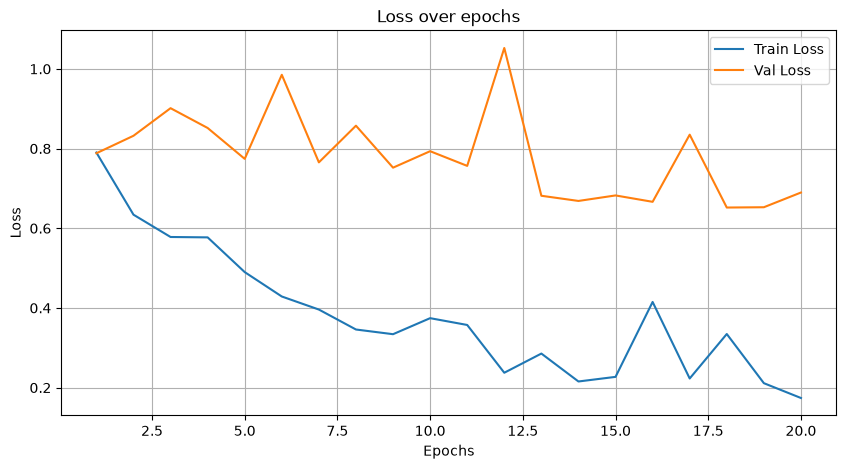

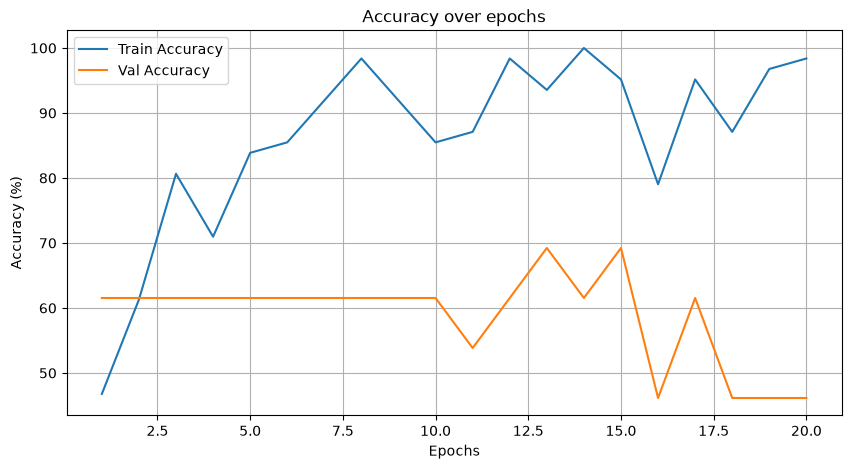

In [47]:
import seaborn as sns
# グラフを描く道具
import matplotlib.pyplot as plt
# 損失と正解率の推移をグラフにする（訓練と検証を比べる）
epochs = range(1, len(train_loss_list) + 1)
plt.figure(figsize=(10, 5))

sns.lineplot(x=epochs, y=train_loss_list, label='Train Loss')
sns.lineplot(x=epochs, y=val_loss_list, label='Val Loss')
plt.title('Loss over epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
sns.lineplot(x=epochs, y=train_acc_list, label='Train Accuracy')
sns.lineplot(x=epochs, y=val_acc_list, label='Val Accuracy')
plt.title('Accuracy over epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.show()

### コードテンプレート⑫：テストデータでの評価

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
print(f'Accuracy: {correct / total * 100:.2f}% ')
```

</details>

In [48]:
model.eval()   # 評価モード（学習のときだけ働く Dropout などを止める）
# テストデータ（学習にも検証にも使っていないデータ）で正解率を求める
correct = 0
total = 0
# 勾配を計算しない（評価だけなので速く，メモリも少なくて済む）
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        # 最も確率の高いクラスを予測とし，正解の数を数える
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
print(f'Accuracy: {correct / total * 100:.2f}% ')

Accuracy: 40.00% 


In [49]:
check("⑫", globals(), size=224)

⑫ OK


## 記録（凍結）

In [50]:
# 記録（凍結のあとと微調整のあとに 1 回ずつ実行する）
from common.logger import ResultLogger
n_all = sum(p.numel() for p in model.parameters())
n_trained = sum(p.numel() for p in model.parameters() if p.requires_grad)
mode = "freeze" if n_trained < n_all else "finetune"
metrics = {"test_accuracy": correct / total, "val_acc_best": max(val_acc_list) / 100,
           "val_acc_last": val_acc_list[-1] / 100, "train_sec": train_sec, "params_trained": n_trained,
           "n_class": len(full_dataset.classes), "n_images": len(full_dataset), "n_test": total}
logger = ResultLogger(None, f"member{MEMBER_NO}", course="c1", day="d5", exercise="ex1", device=device)
logger.log_many(metrics, condition=f"{Path(IMAGE_DIR).name}_ResNet18_{mode}", seed=0)
print(f"ResNet18（{'凍結' if mode == 'freeze' else '微調整'}）：テスト正解率 {correct / total * 100:.1f}%（{total} 枚中 {correct} 枚）"
      f"｜学習したパラメータ {n_trained:,} / {n_all:,}｜{train_sec:.0f} 秒 → {logger.path.name}")

ResNet18（凍結）：テスト正解率 40.0%（15 枚中 6 枚）｜学習したパラメータ 1,026 / 11,177,538｜11 秒 → c1_d5_ex1.csv


## 微調整に替える

⑦を「凍結の `for` 2 つなし」で書き直し，⑧⑨は全部のパラメータを `lr=0.0001` で渡す．⑩〜⑫は上の自分のセルをコピーして貼り，`EPOCHS = 10` にする．

### コードテンプレート⑦：ネットワークの定義（ResNet18・微調整）

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
NUM_CLASSES = len(full_dataset.classes)
from torchvision.models import ResNet18_Weights
model = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, NUM_CLASSES)
model = model.to(device)
dummy_input = torch.randn(1, 3, 224, 224).to(device)
output = model(dummy_input)
print("出力の形状: ", output.size())
```

</details>

In [51]:
NUM_CLASSES = len(full_dataset.classes)                    # クラス数
from torchvision.models import ResNet18_Weights
model = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)   # 学習済みの ResNet18 を読む（初回はダウンロード 45MB）

num_ftrs = model.fc.in_features                            # 最終層に入る数（512）
model.fc = nn.Linear(num_ftrs, NUM_CLASSES)                # 最終層（1000 クラス用）をクラス数に置き換える

model = model.to(device)
dummy_input = torch.randn(1, 3, 224, 224).to(device)       # ダミーデータで出力の形を確かめる
output = model(dummy_input)
print("出力の形状: ", output.size()) 

出力の形状:  torch.Size([1, 2])


In [52]:
check("⑦", globals(), size=224)

ResNet｜出力の形 (1, 2)｜パラメータ数 11,177,538
⑦ OK


### コードテンプレート⑧⑨：損失関数と最適化手法

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)
```

</details>

In [53]:
# 損失関数：予測と正解のずれを測る（分類で標準の交差エントロピー）
criterion = nn.CrossEntropyLoss()
# 最適化手法：損失が小さくなる向きに重みを少しずつ動かす（学習率 0.001）
optimizer = optim.Adam(model.parameters(), lr=0.0001)

In [54]:
check("⑧⑨", globals(), size=224)

⑧⑨ OK


### コードテンプレート⑩：学習

上の⑩をコピーして貼り，`EPOCHS = 10` にする．

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
EPOCHS = 10
train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []
import time
_t0 = time.perf_counter()
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs.data, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    train_loss_list.append(train_loss / train_total)
    train_acc_list.append(100.0 * train_correct / train_total)
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    val_loss_list.append(val_loss / val_total)
    val_acc_list.append(100.0 * val_correct / val_total)
train_sec = time.perf_counter() - _t0
```

</details>

In [55]:
EPOCHS = 10          # 授業では試行①②③とも 20 エポックにそろえる
# エポックごとの損失と正解率を記録するリスト
train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []

# 学習時間を測る（授業で追加）
import time
_t0 = time.perf_counter()
# EPOCHS 回，訓練データ全体を繰り返し学習する
for epoch in range(EPOCHS):
    # 訓練モードにする
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [Train]', leave=False):
        images, labels = images.to(device), labels.to(device)

        # 前回の勾配を消す → 予測 → 損失を計算 → 誤差逆伝播で勾配を求める → 重みを更新
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        # 最も確率の高いクラスを予測とし，正解の数を数える
        _, predicted = torch.max(outputs.data, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    
    train_loss /= train_total
    train_accuracy = 100.0 * train_correct / train_total
    train_loss_list.append(train_loss)
    train_acc_list.append(train_accuracy)
    
    # 評価モードにする：ここからは検証データで確かめる（重みは更新しない）
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    
    # 勾配を計算しない（評価だけなので速く，メモリも少なくて済む）
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f'Epoch {epoch+1}/{EPOCHS} [Val]', leave=False):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    
    val_loss /= val_total
    val_accuracy = 100.0 * val_correct / val_total
    val_loss_list.append(val_loss)
    val_acc_list.append(val_accuracy)

    # エポックごとの損失と正解率を表示する
    print(f'Epoch {epoch+1}/{EPOCHS},'
          f'Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.2f}%,'
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_accuracy:.2f}%  ')

train_sec = time.perf_counter() - _t0
print(f'学習時間: {train_sec:.1f} 秒')

Epoch 1/10,Train Loss: 0.5678, Train Acc: 74.19%,Val Loss: 0.7123, Val Acc: 61.54%  


Epoch 2/10,Train Loss: 0.0704, Train Acc: 100.00%,Val Loss: 0.6826, Val Acc: 61.54%  


Epoch 3/10,Train Loss: 0.0516, Train Acc: 100.00%,Val Loss: 0.6154, Val Acc: 76.92%  


Epoch 4/10,Train Loss: 0.0101, Train Acc: 100.00%,Val Loss: 0.5804, Val Acc: 69.23%  


Epoch 5/10,Train Loss: 0.0178, Train Acc: 100.00%,Val Loss: 0.5879, Val Acc: 76.92%  


Epoch 6/10,Train Loss: 0.0170, Train Acc: 100.00%,Val Loss: 0.6115, Val Acc: 61.54%  


Epoch 7/10,Train Loss: 0.0230, Train Acc: 100.00%,Val Loss: 0.6271, Val Acc: 61.54%  


Epoch 8/10,Train Loss: 0.0067, Train Acc: 100.00%,Val Loss: 0.6399, Val Acc: 61.54%  


Epoch 9/10,Train Loss: 0.0031, Train Acc: 100.00%,Val Loss: 0.6739, Val Acc: 61.54%  


Epoch 10/10,Train Loss: 0.0029, Train Acc: 100.00%,Val Loss: 0.6863, Val Acc: 61.54%  
学習時間: 15.2 秒


In [56]:
check("⑩", globals(), size=224)

⑩ OK


### コードテンプレート⑪：学習結果の可視化

上の⑪をコピーして貼る．

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
epochs = range(1, len(train_loss_list) + 1)
plt.figure(figsize=(10, 4))
sns.lineplot(x=epochs, y=train_acc_list, label='Train Accuracy')
sns.lineplot(x=epochs, y=val_acc_list, label='Val Accuracy')
plt.show()
```

</details>

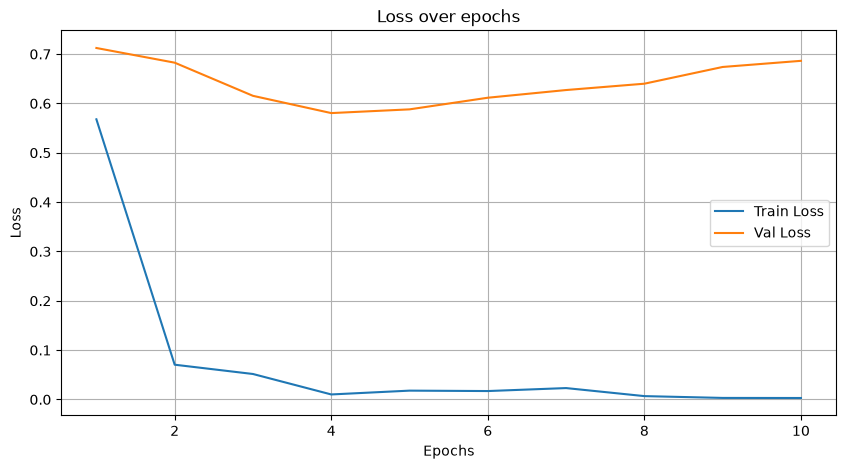

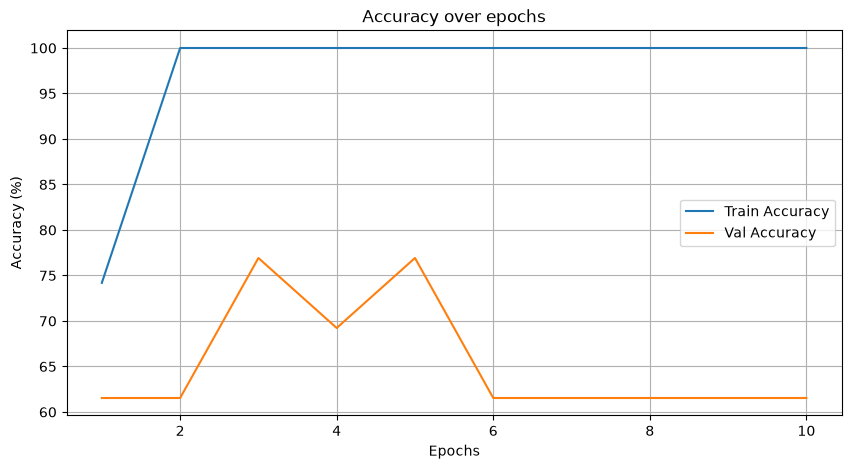

In [57]:
import seaborn as sns
# グラフを描く道具
import matplotlib.pyplot as plt
# 損失と正解率の推移をグラフにする（訓練と検証を比べる）
epochs = range(1, len(train_loss_list) + 1)
plt.figure(figsize=(10, 5))

sns.lineplot(x=epochs, y=train_loss_list, label='Train Loss')
sns.lineplot(x=epochs, y=val_loss_list, label='Val Loss')
plt.title('Loss over epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
sns.lineplot(x=epochs, y=train_acc_list, label='Train Accuracy')
sns.lineplot(x=epochs, y=val_acc_list, label='Val Accuracy')
plt.title('Accuracy over epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
plt.show()

### コードテンプレート⑫：テストデータでの評価

上の⑫をコピーして貼る．

<details><summary>ヒント（分からないときに開く・ほぼ答え）</summary>

```python
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
print(f'Accuracy: {correct / total * 100:.2f}% ')
```

</details>

In [ ]:
check("⑫", globals(), size=224)

## 記録（微調整）

In [ ]:
# 記録（凍結のあとと微調整のあとに 1 回ずつ実行する）
from common.logger import ResultLogger
n_all = sum(p.numel() for p in model.parameters())
n_trained = sum(p.numel() for p in model.parameters() if p.requires_grad)
mode = "freeze" if n_trained < n_all else "finetune"
metrics = {"test_accuracy": correct / total, "val_acc_best": max(val_acc_list) / 100,
           "val_acc_last": val_acc_list[-1] / 100, "train_sec": train_sec, "params_trained": n_trained,
           "n_class": len(full_dataset.classes), "n_images": len(full_dataset), "n_test": total}
logger = ResultLogger(None, f"member{MEMBER_NO}", course="c1", day="d5", exercise="ex1", device=device)
logger.log_many(metrics, condition=f"{Path(IMAGE_DIR).name}_ResNet18_{mode}", seed=0)
print(f"ResNet18（{'凍結' if mode == 'freeze' else '微調整'}）：テスト正解率 {correct / total * 100:.1f}%（{total} 枚中 {correct} 枚）"
      f"｜学習したパラメータ {n_trained:,} / {n_all:,}｜{train_sec:.0f} 秒 → {logger.path.name}")

## 振り返り（提出）

このセルをダブルクリックして，＿＿ に書き込む（それぞれ 1〜2 文）．

1. 第4回の CNN・凍結・微調整のテスト正解率と学習時間（1 回ずつ）：＿＿
2. 凍結で学習したのは最終層の 1,026 個だけ（全体の約 1 万分の 1）．それでも正解率が高かったのはなぜか．最終層の手前までの層が何をしているかに注目して書く：＿＿
3. `check(...)` で `OK` が出なかった（エラーになった）テンプレートの番号と，どう直したか（無ければ「なし」）：＿＿